In [1]:
# ============================================================
# FINAL DATA SCIENCE CAPSTONE PROJECT
# Retail Sales Analysis and Sales Prediction
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Reproducibility
np.random.seed(42)

# Visualization settings
sns.set_theme(style="whitegrid")

# Output folder
OUTPUT_DIR = Path("Analytics_Capstone_Output")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully.")
print("Output folder:", OUTPUT_DIR.resolve())

C:\Users\Nisha\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Libraries imported successfully.
Output folder: C:\Users\Nisha\Analytics_Capstone_Output


In [2]:
business_problem = """
Retail businesses need to understand sales patterns and estimate product demand.

This project analyzes product-wise, region-wise, and monthly sales performance.
It also develops a machine learning model to predict units sold based on
product, region, price, discount, marketing expenditure, and date-related features.
"""

project_objectives = [
    "Analyze retail sales performance",
    "Calculate revenue, cost, profit, and profit margin",
    "Identify product-wise and region-wise trends",
    "Explore monthly sales patterns",
    "Predict units sold using machine learning",
    "Evaluate model performance",
    "Generate business insights and recommendations"
]

print("BUSINESS PROBLEM")
print(business_problem)

print("\nPROJECT OBJECTIVES")
for number, objective in enumerate(project_objectives, start=1):
    print(f"{number}. {objective}")

BUSINESS PROBLEM

Retail businesses need to understand sales patterns and estimate product demand.

This project analyzes product-wise, region-wise, and monthly sales performance.
It also develops a machine learning model to predict units sold based on
product, region, price, discount, marketing expenditure, and date-related features.


PROJECT OBJECTIVES
1. Analyze retail sales performance
2. Calculate revenue, cost, profit, and profit margin
3. Identify product-wise and region-wise trends
4. Explore monthly sales patterns
5. Predict units sold using machine learning
6. Evaluate model performance
7. Generate business insights and recommendations


In [3]:
# Number of records
N = 1200

# Generate dates across approximately three years
date_range = pd.date_range(
    start="2023-01-01",
    end="2025-12-31",
    freq="D"
)

# Product information
product_prices = {
    "Laptop": 60000,
    "Mobile": 25000,
    "Tablet": 18000,
    "Headphones": 3000
}

product_costs = {
    "Laptop": 45000,
    "Mobile": 18000,
    "Tablet": 13000,
    "Headphones": 1800
}

products = list(product_prices.keys())

regions = [
    "West",
    "North",
    "South",
    "East"
]

# Generate random order dates
order_dates = np.random.choice(
    date_range,
    size=N
)

# Generate product and region values
selected_products = np.random.choice(
    products,
    size=N,
    p=[0.20, 0.35, 0.25, 0.20]
)

selected_regions = np.random.choice(
    regions,
    size=N
)

# Generate prices and costs
unit_prices = np.array([
    product_prices[product]
    for product in selected_products
])

unit_costs = np.array([
    product_costs[product]
    for product in selected_products
])

# Generate discount percentages
discounts = np.random.choice(
    [0, 5, 10, 15, 20],
    size=N,
    p=[0.25, 0.25, 0.25, 0.15, 0.10]
)

# Generate marketing expenditure
marketing_spend = np.random.uniform(
    1000,
    15000,
    size=N
)

# Create date-based variables
dates_series = pd.Series(order_dates)

months = dates_series.dt.month.to_numpy()
weekdays = dates_series.dt.dayofweek.to_numpy()

# Product demand baseline
product_demand = {
    "Laptop": 3,
    "Mobile": 8,
    "Tablet": 6,
    "Headphones": 12
}

base_demand = np.array([
    product_demand[product]
    for product in selected_products
])

# Region demand effect
region_effect_map = {
    "West": 3,
    "North": 2,
    "South": 1,
    "East": 0
}

region_effect = np.array([
    region_effect_map[region]
    for region in selected_regions
])

# Discount effect
discount_effect = discounts * 0.20

# Marketing effect
marketing_effect = marketing_spend / 5000

# Seasonal effect
seasonal_effect = np.where(
    np.isin(months, [10, 11, 12]),
    3,
    0
)

# Price effect
price_effect = (
    60000 - unit_prices
) / 20000

# Weekend effect
weekend_effect = np.where(
    weekdays >= 5,
    2,
    0
)

# Random noise
random_noise = np.random.normal(
    loc=0,
    scale=2,
    size=N
)

# Generate the target variable
units_sold = (
    base_demand
    + region_effect
    + discount_effect
    + marketing_effect
    + seasonal_effect
    + price_effect
    + weekend_effect
    + random_noise
)

# Units sold must be positive integers
units_sold = np.maximum(
    1,
    np.round(units_sold)
).astype(int)

# Create the DataFrame
df = pd.DataFrame({
    "Order_ID": np.arange(1001, 1001 + N),
    "Order_Date": pd.to_datetime(order_dates),
    "Region": selected_regions,
    "Product": selected_products,
    "Unit_Price": unit_prices,
    "Unit_Cost": unit_costs,
    "Discount": discounts,
    "Marketing_Spend": np.round(marketing_spend, 2),
    "Units_Sold": units_sold
})

# Sort chronologically
df = df.sort_values(
    "Order_Date"
).reset_index(drop=True)

print("Dataset created successfully.")
print(df.head())
print("\nDataset dimensions:", df.shape)

Dataset created successfully.
   Order_ID Order_Date Region     Product  Unit_Price  Unit_Cost  Discount  \
0      1559 2023-01-01   East  Headphones        3000       1800         0   
1      1743 2023-01-01   West      Tablet       18000      13000        10   
2      1146 2023-01-02   East      Mobile       25000      18000         0   
3      1189 2023-01-02  South      Tablet       18000      13000         5   
4      2178 2023-01-03  North      Laptop       60000      45000         5   

   Marketing_Spend  Units_Sold  
0          3402.35          19  
1          9211.16          17  
2         10458.70          11  
3         13530.91          14  
4         14235.20           9  

Dataset dimensions: (1200, 9)


In [4]:
# Calculate revenue after discount
df["Revenue"] = (
    df["Units_Sold"]
    * df["Unit_Price"]
    * (1 - df["Discount"] / 100)
)

# Calculate product cost
df["Total_Cost"] = (
    df["Units_Sold"]
    * df["Unit_Cost"]
)

# Calculate profit before other operating expenses
df["Profit"] = (
    df["Revenue"]
    - df["Total_Cost"]
)

# Calculate profit margin
df["Profit_Margin"] = np.where(
    df["Revenue"] != 0,
    (df["Profit"] / df["Revenue"]) * 100,
    np.nan
)

# Create date-related features
df["Month"] = df["Order_Date"].dt.month
df["Day_of_Week"] = df["Order_Date"].dt.dayofweek
df["Quarter"] = df["Order_Date"].dt.quarter
df["Is_Weekend"] = (
    df["Day_of_Week"] >= 5
).astype(int)

print(df.head())

   Order_ID Order_Date Region     Product  Unit_Price  Unit_Cost  Discount  \
0      1559 2023-01-01   East  Headphones        3000       1800         0   
1      1743 2023-01-01   West      Tablet       18000      13000        10   
2      1146 2023-01-02   East      Mobile       25000      18000         0   
3      1189 2023-01-02  South      Tablet       18000      13000         5   
4      2178 2023-01-03  North      Laptop       60000      45000         5   

   Marketing_Spend  Units_Sold   Revenue  Total_Cost    Profit  Profit_Margin  \
0          3402.35          19   57000.0       34200   22800.0      40.000000   
1          9211.16          17  275400.0      221000   54400.0      19.753086   
2         10458.70          11  275000.0      198000   77000.0      28.000000   
3         13530.91          14  239400.0      182000   57400.0      23.976608   
4         14235.20           9  513000.0      405000  108000.0      21.052632   

   Month  Day_of_Week  Quarter  Is_Weekend  

In [5]:
print("FIRST FIVE RECORDS")
print(df.head())

print("\nLAST FIVE RECORDS")
print(df.tail())

print("\nDATASET SHAPE")
print(df.shape)

print("\nCOLUMN INFORMATION")
df.info()

print("\nNUMERICAL SUMMARY")
print(df.describe())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nUNIQUE PRODUCTS")
print(df["Product"].unique())

print("\nUNIQUE REGIONS")
print(df["Region"].unique())

FIRST FIVE RECORDS
   Order_ID Order_Date Region     Product  Unit_Price  Unit_Cost  Discount  \
0      1559 2023-01-01   East  Headphones        3000       1800         0   
1      1743 2023-01-01   West      Tablet       18000      13000        10   
2      1146 2023-01-02   East      Mobile       25000      18000         0   
3      1189 2023-01-02  South      Tablet       18000      13000         5   
4      2178 2023-01-03  North      Laptop       60000      45000         5   

   Marketing_Spend  Units_Sold   Revenue  Total_Cost    Profit  Profit_Margin  \
0          3402.35          19   57000.0       34200   22800.0      40.000000   
1          9211.16          17  275400.0      221000   54400.0      19.753086   
2         10458.70          11  275000.0      198000   77000.0      28.000000   
3         13530.91          14  239400.0      182000   57400.0      23.976608   
4         14235.20           9  513000.0      405000  108000.0      21.052632   

   Month  Day_of_Week  Qu

In [6]:
# Create a separate cleaned DataFrame
clean_df = df.copy()

# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates()

# Remove duplicate order IDs if they exist
clean_df = clean_df.drop_duplicates(
    subset=["Order_ID"],
    keep="first"
)

# Convert the order date to datetime
clean_df["Order_Date"] = pd.to_datetime(
    clean_df["Order_Date"],
    errors="coerce"
)

# Convert numeric columns safely
numeric_columns = [
    "Unit_Price",
    "Unit_Cost",
    "Discount",
    "Marketing_Spend",
    "Units_Sold"
]

for column in numeric_columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column],
        errors="coerce"
    )

# Remove rows with missing essential information
essential_columns = [
    "Order_ID",
    "Order_Date",
    "Region",
    "Product",
    "Unit_Price",
    "Units_Sold"
]

clean_df = clean_df.dropna(
    subset=essential_columns
)

# Validate values
clean_df = clean_df[
    (clean_df["Units_Sold"] > 0)
    & (clean_df["Unit_Price"] >= 0)
    & (clean_df["Unit_Cost"] >= 0)
    & (clean_df["Marketing_Spend"] >= 0)
    & (clean_df["Discount"].between(0, 100))
].copy()

# Recalculate derived columns after cleaning
clean_df["Revenue"] = (
    clean_df["Units_Sold"]
    * clean_df["Unit_Price"]
    * (1 - clean_df["Discount"] / 100)
)

clean_df["Total_Cost"] = (
    clean_df["Units_Sold"]
    * clean_df["Unit_Cost"]
)

clean_df["Profit"] = (
    clean_df["Revenue"]
    - clean_df["Total_Cost"]
)

clean_df["Profit_Margin"] = np.where(
    clean_df["Revenue"] != 0,
    clean_df["Profit"] / clean_df["Revenue"] * 100,
    np.nan
)

# Recreate date features
clean_df["Month"] = clean_df["Order_Date"].dt.month
clean_df["Day_of_Week"] = (
    clean_df["Order_Date"].dt.dayofweek
)
clean_df["Quarter"] = clean_df["Order_Date"].dt.quarter
clean_df["Is_Weekend"] = (
    clean_df["Day_of_Week"] >= 5
).astype(int)

clean_df = clean_df.sort_values(
    "Order_Date"
).reset_index(drop=True)

print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Missing values after cleaning:")
print(clean_df.isnull().sum())

Original rows: 1200
Cleaned rows: 1200
Missing values after cleaning:
Order_ID           0
Order_Date         0
Region             0
Product            0
Unit_Price         0
Unit_Cost          0
Discount           0
Marketing_Spend    0
Units_Sold         0
Revenue            0
Total_Cost         0
Profit             0
Profit_Margin      0
Month              0
Day_of_Week        0
Quarter            0
Is_Weekend         0
dtype: int64


In [7]:
total_revenue = clean_df["Revenue"].sum()
total_cost = clean_df["Total_Cost"].sum()
total_profit = clean_df["Profit"].sum()

total_units = clean_df["Units_Sold"].sum()
total_orders = clean_df["Order_ID"].nunique()

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0
    else 0
)

overall_profit_margin = (
    total_profit / total_revenue * 100
    if total_revenue != 0
    else 0
)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Cost",
        "Total Profit",
        "Total Units Sold",
        "Total Orders",
        "Average Order Value",
        "Overall Profit Margin (%)"
    ],
    "Value": [
        total_revenue,
        total_cost,
        total_profit,
        total_units,
        total_orders,
        average_order_value,
        overall_profit_margin
    ]
})

print(kpi_summary)

kpi_summary.to_csv(
    OUTPUT_DIR / "kpi_summary.csv",
    index=False
)

                         KPI         Value
0              Total Revenue  3.565634e+08
1                 Total Cost  2.839588e+08
2               Total Profit  7.260460e+07
3           Total Units Sold  1.792900e+04
4               Total Orders  1.200000e+03
5        Average Order Value  2.971362e+05
6  Overall Profit Margin (%)  2.036233e+01


In [8]:
product_analysis = (
    clean_df
    .groupby("Product")
    .agg(
        Units_Sold=("Units_Sold", "sum"),
        Revenue=("Revenue", "sum"),
        Total_Cost=("Total_Cost", "sum"),
        Profit=("Profit", "sum"),
        Average_Unit_Price=("Unit_Price", "mean")
    )
    .reset_index()
)

product_analysis["Profit_Margin_Percent"] = np.where(
    product_analysis["Revenue"] != 0,
    product_analysis["Profit"]
    / product_analysis["Revenue"] * 100,
    np.nan
)

product_analysis = product_analysis.sort_values(
    "Revenue",
    ascending=False
)

print(product_analysis)

product_analysis.to_csv(
    OUTPUT_DIR / "product_analysis.csv",
    index=False
)

top_revenue_product = product_analysis.iloc[0]["Product"]

top_profit_product = product_analysis.loc[
    product_analysis["Profit"].idxmax(),
    "Product"
]

print("Product with highest revenue:", top_revenue_product)
print("Product with highest profit:", top_profit_product)

      Product  Units_Sold      Revenue  Total_Cost      Profit  \
2      Mobile        6561  149438750.0   118098000  31340750.0   
1      Laptop        2226  121986000.0   100170000  21816000.0   
3      Tablet        4396   72017100.0    57148000  14869100.0   
0  Headphones        4746   13121550.0     8542800   4578750.0   

   Average_Unit_Price  Profit_Margin_Percent  
2             25000.0              20.972305  
1             60000.0              17.884019  
3             18000.0              20.646624  
0              3000.0              34.894887  
Product with highest revenue: Mobile
Product with highest profit: Mobile


In [9]:
region_analysis = (
    clean_df
    .groupby("Region")
    .agg(
        Units_Sold=("Units_Sold", "sum"),
        Revenue=("Revenue", "sum"),
        Profit=("Profit", "sum"),
        Number_of_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

region_analysis["Revenue_Share_Percent"] = (
    region_analysis["Revenue"]
    / region_analysis["Revenue"].sum()
    * 100
)

region_analysis = region_analysis.sort_values(
    "Revenue",
    ascending=False
)

print(region_analysis)

region_analysis.to_csv(
    OUTPUT_DIR / "region_analysis.csv",
    index=False
)

best_region = region_analysis.iloc[0]["Region"]

print("Region with highest revenue:", best_region)

  Region  Units_Sold      Revenue      Profit  Number_of_Orders  \
3   West        5152  104655300.0  21151300.0               315   
2  South        4315   87831450.0  17702850.0               303   
1  North        4373   85124100.0  17757300.0               283   
0   East        4089   78952550.0  15993150.0               299   

   Revenue_Share_Percent  
3              29.351106  
2              24.632772  
1              23.873482  
0              22.142640  
Region with highest revenue: West


In [10]:
monthly_analysis = (
    clean_df
    .assign(
        Month_Start=lambda data:
        data["Order_Date"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("Month_Start")
    .agg(
        Revenue=("Revenue", "sum"),
        Profit=("Profit", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Orders=("Order_ID", "nunique")
    )
    .reset_index()
    .sort_values("Month_Start")
)

monthly_analysis["Revenue_Growth_Percent"] = (
    monthly_analysis["Revenue"]
    .pct_change()
    * 100
)

print(monthly_analysis)

monthly_analysis.to_csv(
    OUTPUT_DIR / "monthly_analysis.csv",
    index=False
)

   Month_Start     Revenue     Profit  Units_Sold  Orders  \
0   2023-01-01  13922700.0  3025900.0         674      45   
1   2023-02-01  10944250.0  2131650.0         544      38   
2   2023-03-01   7836850.0  1779250.0         386      31   
3   2023-04-01  11343250.0  1972850.0         537      36   
4   2023-05-01  11504700.0  2497300.0         515      37   
5   2023-06-01   7099350.0  1484550.0         483      30   
6   2023-07-01   6553450.0  1433850.0         409      28   
7   2023-08-01   7727200.0  1684200.0         478      32   
8   2023-09-01   7959700.0  1487700.0         458      30   
9   2023-10-01   8601250.0  1536050.0         363      22   
10  2023-11-01   8963950.0  1863350.0         445      25   
11  2023-12-01  10630850.0  2168650.0         531      29   
12  2024-01-01   7410600.0  1575200.0         437      29   
13  2024-02-01   8347300.0  1582300.0         398      30   
14  2024-03-01   6387700.0  1361100.0         392      27   
15  2024-04-01   6720500

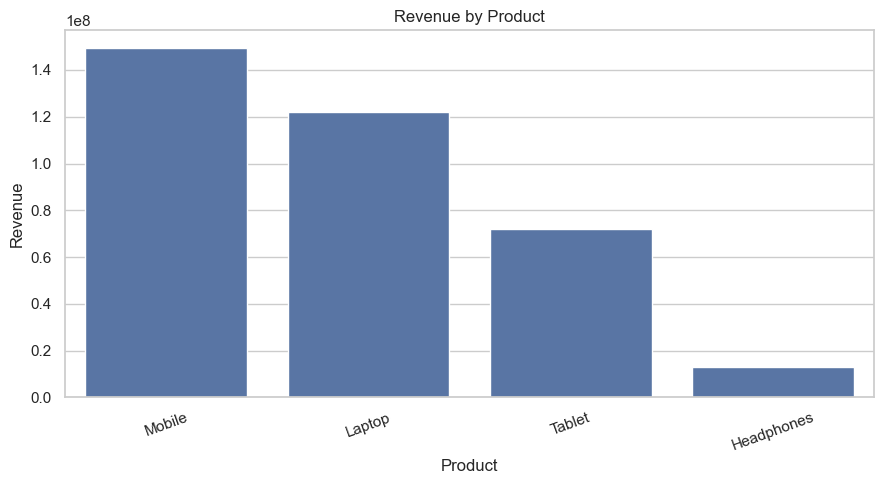

In [11]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=product_analysis,
    x="Product",
    y="Revenue"
)

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "revenue_by_product.png",
    dpi=300
)

plt.show()

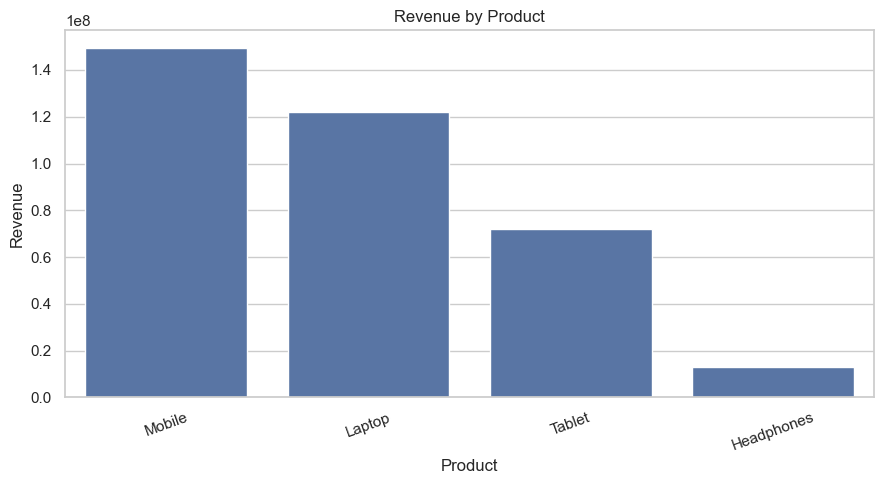

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=product_analysis,
    x="Product",
    y="Revenue"
)

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "revenue_by_product.png",
    dpi=300
)

plt.show()

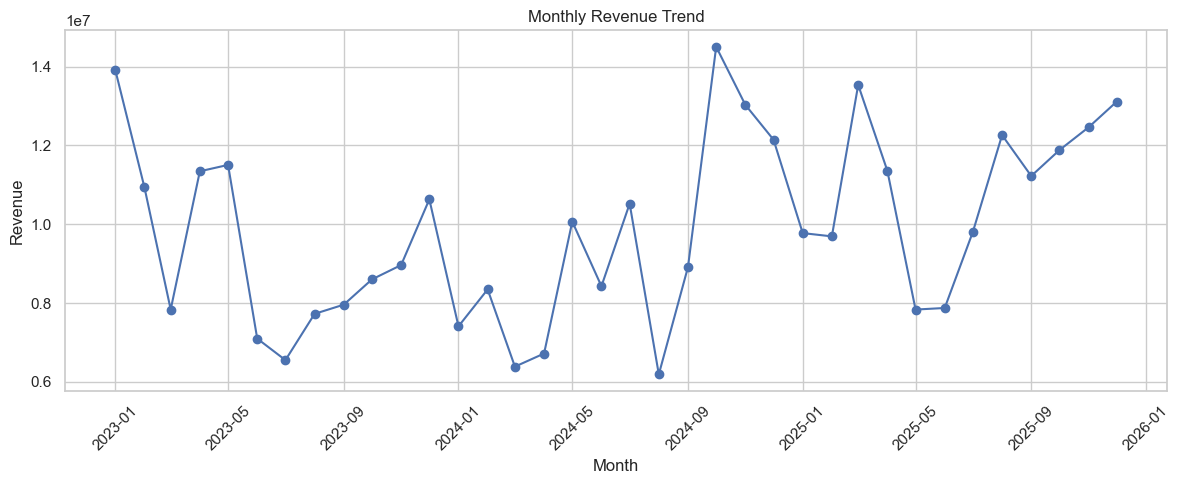

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_analysis["Month_Start"],
    monthly_analysis["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_revenue_trend.png",
    dpi=300
)

plt.show()

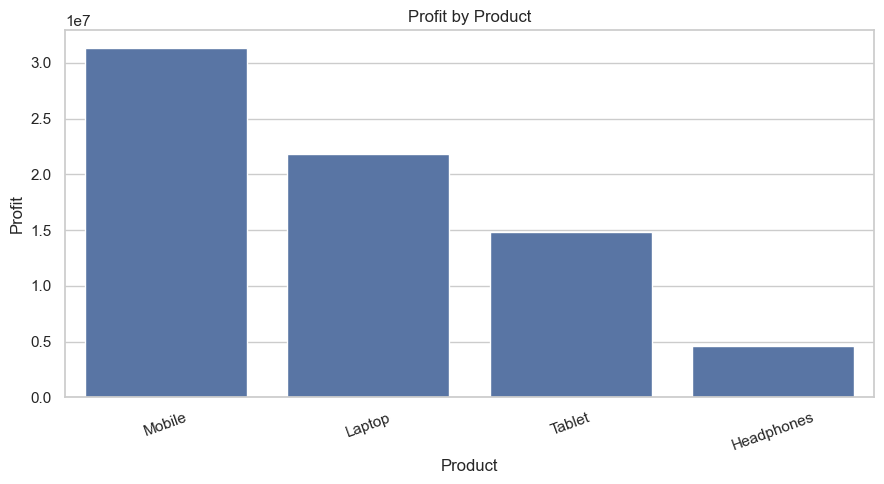

In [14]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=product_analysis,
    x="Product",
    y="Profit"
)

plt.title("Profit by Product")
plt.xlabel("Product")
plt.ylabel("Profit")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "profit_by_product.png",
    dpi=300
)

plt.show()

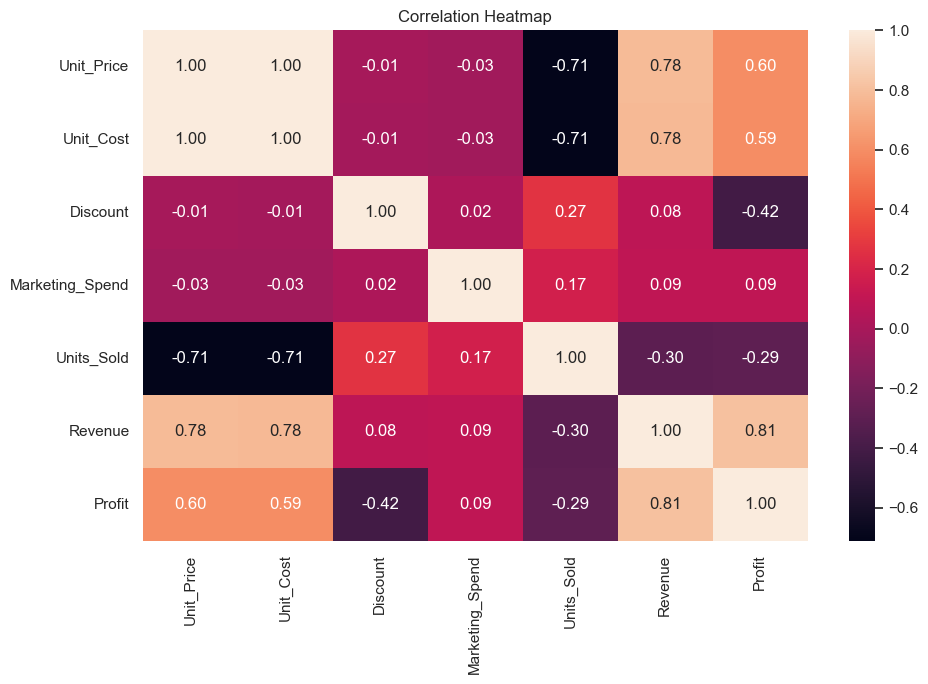

In [15]:
numeric_data = clean_df[
    [
        "Unit_Price",
        "Unit_Cost",
        "Discount",
        "Marketing_Spend",
        "Units_Sold",
        "Revenue",
        "Profit"
    ]
]

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "correlation_heatmap.png",
    dpi=300
)

plt.show()

In [16]:
# Define input features
feature_columns = [
    "Product",
    "Region",
    "Unit_Price",
    "Discount",
    "Marketing_Spend",
    "Month",
    "Day_of_Week",
    "Quarter",
    "Is_Weekend"
]

target_column = "Units_Sold"

# Ensure chronological ordering
model_df = clean_df.sort_values(
    "Order_Date"
).reset_index(drop=True)

X = model_df[feature_columns]
y = model_df[target_column]

# Chronological 80/20 split
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(
    model_df["Order_Date"].iloc[0],
    "to",
    model_df["Order_Date"].iloc[split_index - 1]
)

print("\nTesting period:")
print(
    model_df["Order_Date"].iloc[split_index],
    "to",
    model_df["Order_Date"].iloc[-1]
)

Training records: 960
Testing records: 240

Training period:
2023-01-01 00:00:00 to 2025-06-11 00:00:00

Testing period:
2025-06-12 00:00:00 to 2025-12-31 00:00:00


In [17]:
categorical_features = [
    "Product",
    "Region"
]

numeric_features = [
    "Unit_Price",
    "Discount",
    "Marketing_Spend",
    "Month",
    "Day_of_Week",
    "Quarter",
    "Is_Weekend"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [18]:
# Baseline model: predicts the mean of the training target
baseline_model = DummyRegressor(
    strategy="mean"
)

baseline_model.fit(
    X_train,
    y_train
)

baseline_predictions = baseline_model.predict(
    X_test
)

# Random Forest model
random_forest = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", random_forest)
    ]
)

# Train the complete pipeline
model.fit(
    X_train,
    y_train
)

# Predict on unseen test data
predictions = model.predict(
    X_test
)

print("Baseline model and Random Forest model trained.")

Baseline model and Random Forest model trained.


In [19]:
def evaluate_regression_model(
    actual_values,
    predicted_values,
    model_name
):
    mae = mean_absolute_error(
        actual_values,
        predicted_values
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_values,
            predicted_values
        )
    )

    r2 = r2_score(
        actual_values,
        predicted_values
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


baseline_metrics = evaluate_regression_model(
    y_test,
    baseline_predictions,
    "Mean Baseline"
)

random_forest_metrics = evaluate_regression_model(
    y_test,
    predictions,
    "Random Forest"
)

model_comparison = pd.DataFrame([
    baseline_metrics,
    random_forest_metrics
])

print(model_comparison)

model_comparison.to_csv(
    OUTPUT_DIR / "model_evaluation.csv",
    index=False
)

           Model       MAE      RMSE        R2
0  Mean Baseline  4.055599  5.046759 -0.006556
1  Random Forest  1.737739  2.221981  0.804884


   Actual_Units_Sold  Predicted_Units_Sold  Prediction_Error  Absolute_Error
0                 15             15.762828         -0.762828        0.762828
1                 14             14.487122         -0.487122        0.487122
2                  7              6.792754          0.207246        0.207246
3                 15             12.537587          2.462413        2.462413
4                 17             14.092230          2.907770        2.907770
5                  7              8.238030         -1.238030        1.238030
6                 18             17.967857          0.032143        0.032143
7                 14             13.459601          0.540399        0.540399
8                  3              5.604632         -2.604632        2.604632
9                 16             15.487875          0.512125        0.512125


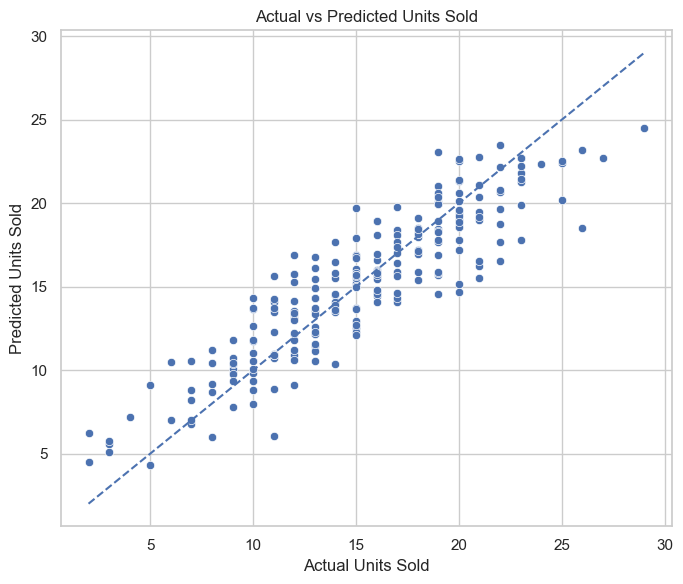

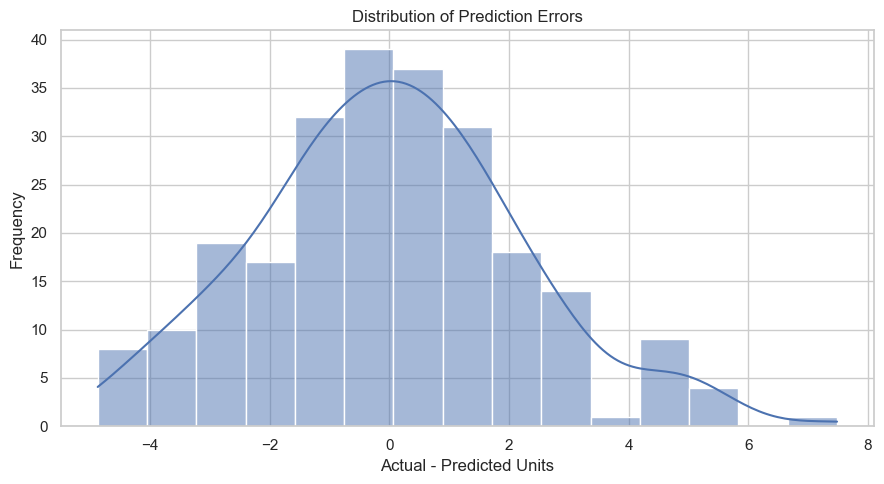

In [20]:
# Create a prediction comparison table
prediction_results = pd.DataFrame({
    "Actual_Units_Sold": y_test.to_numpy(),
    "Predicted_Units_Sold": predictions
})

prediction_results["Prediction_Error"] = (
    prediction_results["Actual_Units_Sold"]
    - prediction_results["Predicted_Units_Sold"]
)

prediction_results["Absolute_Error"] = (
    prediction_results["Prediction_Error"].abs()
)

print(prediction_results.head(10))

prediction_results.to_csv(
    OUTPUT_DIR / "prediction_results.csv",
    index=False
)

# Actual versus predicted chart
plt.figure(figsize=(7, 6))

sns.scatterplot(
    data=prediction_results,
    x="Actual_Units_Sold",
    y="Predicted_Units_Sold"
)

min_value = min(
    prediction_results["Actual_Units_Sold"].min(),
    prediction_results["Predicted_Units_Sold"].min()
)

max_value = max(
    prediction_results["Actual_Units_Sold"].max(),
    prediction_results["Predicted_Units_Sold"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Units Sold")
plt.xlabel("Actual Units Sold")
plt.ylabel("Predicted Units Sold")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "actual_vs_predicted.png",
    dpi=300
)

plt.show()

# Prediction error distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    prediction_results["Prediction_Error"],
    kde=True
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual - Predicted Units")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "prediction_error_distribution.png",
    dpi=300
)

plt.show()

                            Feature  Importance
8               numeric__Unit_Price    0.314742
1       categorical__Product_Laptop    0.192877
0   categorical__Product_Headphones    0.106945
10         numeric__Marketing_Spend    0.085169
9                 numeric__Discount    0.081816
11                   numeric__Month    0.066492
12             numeric__Day_of_Week    0.035506
13                 numeric__Quarter    0.034666
7          categorical__Region_West    0.025981
4          categorical__Region_East    0.020698
14              numeric__Is_Weekend    0.011762
5         categorical__Region_North    0.006577
2       categorical__Product_Mobile    0.005938
6         categorical__Region_South    0.005905
3       categorical__Product_Tablet    0.004925


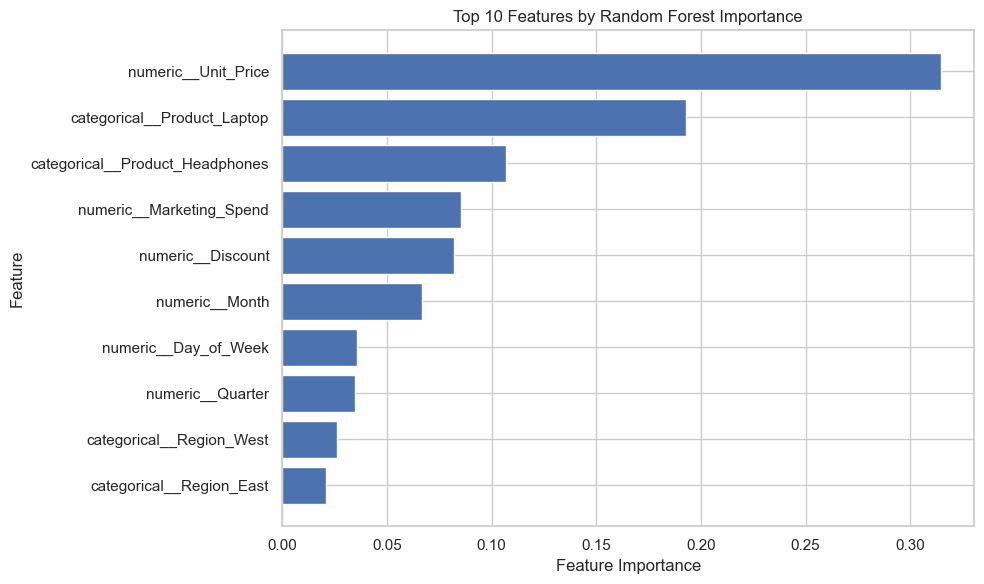

In [21]:
# Extract the fitted preprocessing object
fitted_preprocessor = model.named_steps["preprocessor"]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Random Forest feature importance
feature_importances = (
    model.named_steps["regressor"].feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
}).sort_values(
    "Importance",
    ascending=False
)

print(importance_df.head(15))

importance_df.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False
)

# Visualize the 10 most important features
top_features = importance_df.head(10).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Features by Random Forest Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "feature_importance.png",
    dpi=300
)

plt.show()

In [22]:
# Identify top-performing product and region
top_revenue_product_row = product_analysis.loc[
    product_analysis["Revenue"].idxmax()
]

top_profit_product_row = product_analysis.loc[
    product_analysis["Profit"].idxmax()
]

top_region_row = region_analysis.loc[
    region_analysis["Revenue"].idxmax()
]

# Find the month with the highest revenue
best_month_row = monthly_analysis.loc[
    monthly_analysis["Revenue"].idxmax()
]

# Create insights using actual calculated results
insights = [
    (
        f"Total revenue recorded in the dataset was "
        f"{total_revenue:,.2f}."
    ),
    (
        f"Total profit before other operating expenses was "
        f"{total_profit:,.2f}."
    ),
    (
        f"The product with the highest revenue was "
        f"{top_revenue_product_row['Product']}."
    ),
    (
        f"The product with the highest profit was "
        f"{top_profit_product_row['Product']}."
    ),
    (
        f"The region with the highest revenue was "
        f"{top_region_row['Region']}."
    ),
    (
        f"The highest-revenue month in the dataset was "
        f"{best_month_row['Month_Start'].strftime('%B %Y')}."
    ),
    (
        f"Random Forest test MAE was "
        f"{random_forest_metrics['MAE']:.2f} units."
    ),
    (
        f"Random Forest test RMSE was "
        f"{random_forest_metrics['RMSE']:.2f} units."
    ),
    (
        f"Random Forest test R-squared was "
        f"{random_forest_metrics['R2']:.3f}."
    )
]

print("BUSINESS INSIGHTS\n")

for number, insight in enumerate(insights, start=1):
    print(f"{number}. {insight}")

with open(
    OUTPUT_DIR / "business_insights.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write("BUSINESS INSIGHTS\n\n")

    for number, insight in enumerate(insights, start=1):
        file.write(f"{number}. {insight}\n")

BUSINESS INSIGHTS

1. Total revenue recorded in the dataset was 356,563,400.00.
2. Total profit before other operating expenses was 72,604,600.00.
3. The product with the highest revenue was Mobile.
4. The product with the highest profit was Mobile.
5. The region with the highest revenue was West.
6. The highest-revenue month in the dataset was October 2024.
7. Random Forest test MAE was 1.74 units.
8. Random Forest test RMSE was 2.22 units.
9. Random Forest test R-squared was 0.805.


In [23]:
recommendations = pd.DataFrame([
    {
        "Area": "Inventory Planning",
        "Finding": "Products have different demand levels.",
        "Recommendation": (
            "Use historical demand and model predictions to "
            "support inventory planning."
        ),
        "Priority": "High"
    },
    {
        "Area": "Product Performance",
        "Finding": "Revenue and profit rankings may differ.",
        "Recommendation": (
            "Evaluate both revenue and profit before prioritizing products."
        ),
        "Priority": "High"
    },
    {
        "Area": "Regional Performance",
        "Finding": "Sales differ across geographic regions.",
        "Recommendation": (
            "Investigate regional demand, distribution, and marketing "
            "before allocating additional resources."
        ),
        "Priority": "Medium"
    },
    {
        "Area": "Discount Strategy",
        "Finding": "Discounts may be associated with changes in demand.",
        "Recommendation": (
            "Evaluate promotional effectiveness using sales volume "
            "and profit margin together."
        ),
        "Priority": "Medium"
    },
    {
        "Area": "Model Monitoring",
        "Finding": "Prediction errors may change over time.",
        "Recommendation": (
            "Track model performance on new data and retrain when "
            "necessary."
        ),
        "Priority": "High"
    }
])

print(recommendations)

recommendations.to_csv(
    OUTPUT_DIR / "business_recommendations.csv",
    index=False
)

                   Area                                            Finding  \
0    Inventory Planning             Products have different demand levels.   
1   Product Performance            Revenue and profit rankings may differ.   
2  Regional Performance            Sales differ across geographic regions.   
3     Discount Strategy  Discounts may be associated with changes in de...   
4      Model Monitoring            Prediction errors may change over time.   

                                      Recommendation Priority  
0  Use historical demand and model predictions to...     High  
1  Evaluate both revenue and profit before priori...     High  
2  Investigate regional demand, distribution, and...   Medium  
3  Evaluate promotional effectiveness using sales...   Medium  
4  Track model performance on new data and retrai...     High  


In [24]:
executive_summary = f"""
FINAL DATA SCIENCE CAPSTONE PROJECT
Retail Sales Analysis and Sales Prediction Using Machine Learning

1. PROJECT OBJECTIVE
The project analyzes retail sales performance and develops a machine
learning model to predict units sold.

2. DATASET
Number of cleaned records: {len(clean_df)}
Number of products: {clean_df["Product"].nunique()}
Number of regions: {clean_df["Region"].nunique()}

3. BUSINESS PERFORMANCE
Total Revenue: {total_revenue:,.2f}
Total Cost: {total_cost:,.2f}
Total Profit: {total_profit:,.2f}
Total Units Sold: {total_units:,}
Total Orders: {total_orders:,}
Average Order Value: {average_order_value:,.2f}
Overall Profit Margin: {overall_profit_margin:.2f}%

4. PRODUCT AND REGIONAL FINDINGS
Highest-Revenue Product: {top_revenue_product_row["Product"]}
Highest-Profit Product: {top_profit_product_row["Product"]}
Highest-Revenue Region: {top_region_row["Region"]}

5. MACHINE LEARNING RESULTS
Algorithm: Random Forest Regressor
Target: Units Sold
MAE: {random_forest_metrics["MAE"]:.2f}
RMSE: {random_forest_metrics["RMSE"]:.2f}
R-squared: {random_forest_metrics["R2"]:.3f}

6. IMPORTANT INTERPRETATION
These results are based on a synthetic demonstration dataset.
They demonstrate the project workflow and must not be treated as
verified real-world retail performance.

7. RECOMMENDATIONS
Use sales analysis and prediction to support inventory planning.
Evaluate products using revenue, profit, and margin together.
Monitor model errors before using predictions in business decisions.
Replace the demonstration dataset with authentic business data
for a real-world evaluation.
"""

print(executive_summary)

with open(
    OUTPUT_DIR / "executive_summary.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(executive_summary)


FINAL DATA SCIENCE CAPSTONE PROJECT
Retail Sales Analysis and Sales Prediction Using Machine Learning

1. PROJECT OBJECTIVE
The project analyzes retail sales performance and develops a machine
learning model to predict units sold.

2. DATASET
Number of cleaned records: 1200
Number of products: 4
Number of regions: 4

3. BUSINESS PERFORMANCE
Total Revenue: 356,563,400.00
Total Cost: 283,958,800.00
Total Profit: 72,604,600.00
Total Units Sold: 17,929
Total Orders: 1,200
Average Order Value: 297,136.17
Overall Profit Margin: 20.36%

4. PRODUCT AND REGIONAL FINDINGS
Highest-Revenue Product: Mobile
Highest-Profit Product: Mobile
Highest-Revenue Region: West

5. MACHINE LEARNING RESULTS
Algorithm: Random Forest Regressor
Target: Units Sold
MAE: 1.74
RMSE: 2.22
R-squared: 0.805

6. IMPORTANT INTERPRETATION
These results are based on a synthetic demonstration dataset.
They demonstrate the project workflow and must not be treated as
verified real-world retail performance.

7. RECOMMENDATIONS
U

In [25]:
# Save the cleaned dataset
clean_df.to_csv(
    OUTPUT_DIR / "cleaned_retail_sales.csv",
    index=False
)

# Save product and region summaries
product_analysis.to_csv(
    OUTPUT_DIR / "product_analysis.csv",
    index=False
)

region_analysis.to_csv(
    OUTPUT_DIR / "region_analysis.csv",
    index=False
)

# Save monthly analysis
monthly_analysis.to_csv(
    OUTPUT_DIR / "monthly_analysis.csv",
    index=False
)

# Save model evaluation
model_comparison.to_csv(
    OUTPUT_DIR / "model_evaluation.csv",
    index=False
)

# Save recommendations
recommendations.to_csv(
    OUTPUT_DIR / "business_recommendations.csv",
    index=False
)

print("Project execution completed.")
print("All outputs are saved in:")
print(OUTPUT_DIR.resolve())

print("\nGenerated files:")

for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(output_file.name)

Project execution completed.
All outputs are saved in:
C:\Users\Nisha\Analytics_Capstone_Output

Generated files:
actual_vs_predicted.png
business_insights.txt
business_recommendations.csv
cleaned_retail_sales.csv
correlation_heatmap.png
executive_summary.txt
feature_importance.csv
feature_importance.png
kpi_summary.csv
model_evaluation.csv
monthly_analysis.csv
monthly_revenue_trend.png
prediction_error_distribution.png
prediction_results.csv
product_analysis.csv
profit_by_product.png
region_analysis.csv
revenue_by_product.png
